# 02 - Churn-proxy & CLV model walkthrough
Reads artifacts from `make train` (`churn train`, `churn clv`, `churn target`). **Churn = no purchase in the 90 days after a cutoff - a proxy, not an observed cancellation.**

In [1]:
import os, json, duckdb, pandas as pd, numpy as np, matplotlib.pyplot as plt
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20)
con = duckdb.connect('data/processed/retail.duckdb', read_only=True)
art = 'artifacts/'

## Time-aware design
Train on 4 snapshot cutoffs, choose hyper-parameters & calibration on 2011-06-01, report on 2011-09-01. Every label window ends before the next split's cutoff.

In [2]:
tr = pd.read_parquet(art + 'snapshot_train.parquet'); va = pd.read_parquet(art + 'snapshot_valid.parquet')
te = pd.read_parquet(art + 'snapshot_test.parquet')
pd.DataFrame({'rows': [len(tr), len(va), len(te)], 'churn_rate': [tr.churned.mean(), va.churned.mean(), te.churned.mean()]},
             index=['train (4 cutoffs)', 'valid 2011-06-01', 'test 2011-09-01'])

,rows,churn_rate
train (4 cutoffs),14482,0.569466
valid 2011-06-01,4324,0.633673
test 2011-09-01,4323,0.504511


In [3]:
tr.groupby('cutoff').churned.agg(['size', 'mean'])

,size,mean
cutoff,,
2010-06-01,2684,0.502981
2010-09-01,3299,0.416793
2010-12-01,4239,0.668318
2011-03-01,4260,0.631221


## Leakage check in-notebook
Features at a cutoff are computed only from rows dated before it.

In [4]:
from churn_clv.features import build_snapshot, FEATURE_COLUMNS
s = build_snapshot(con, '2011-09-01')
last = con.execute("SELECT customer_id, MAX(invoice_date) d FROM fct_invoices WHERE invoice_date < DATE '2011-09-01' GROUP BY 1").df()
chk = s.merge(last, on='customer_id')
assert ((pd.Timestamp('2011-09-01') - pd.to_datetime(chk.d)).dt.days == chk.recency_days).all(); print('recency consistent with pre-cutoff data only')

recency consistent with pre-cutoff data only


## Metrics vs baselines (test cutoff)

In [5]:
pd.read_csv(art + 'model_metrics.csv').query('split=="test"').round(3)

,model,calibration,split,roc_auc,pr_auc,brier,log_loss,ece,lift_top10,lift_top20,gain_top20,gain_top30,base_rate
1,Recency rule,none,test,0.706,0.670,0.235,0.670,0.135,1.447,1.439,0.288,0.422,0.505
3,RFM heuristic,none,test,0.750,0.715,0.204,0.595,0.044,1.639,1.547,0.309,0.449,0.505
5,Logistic regression,none,test,0.769,0.737,0.202,0.587,0.093,1.639,1.519,0.304,0.442,0.505
6,Logistic regression,isotonic,test,0.768,0.728,0.210,0.621,0.124,1.634,1.519,0.304,0.440,0.505
7,Logistic regression,platt,test,0.769,0.737,0.209,0.609,0.123,1.639,1.519,0.304,0.442,0.505
9,LightGBM,none,test,0.765,0.727,0.211,0.611,0.128,1.543,1.480,0.296,0.444,0.505
10,LightGBM,isotonic,test,0.764,0.717,0.214,0.631,0.135,1.556,1.480,0.296,0.437,0.505
11,LightGBM,platt,test,0.765,0.727,0.214,0.622,0.133,1.543,1.480,0.296,0.444,0.505


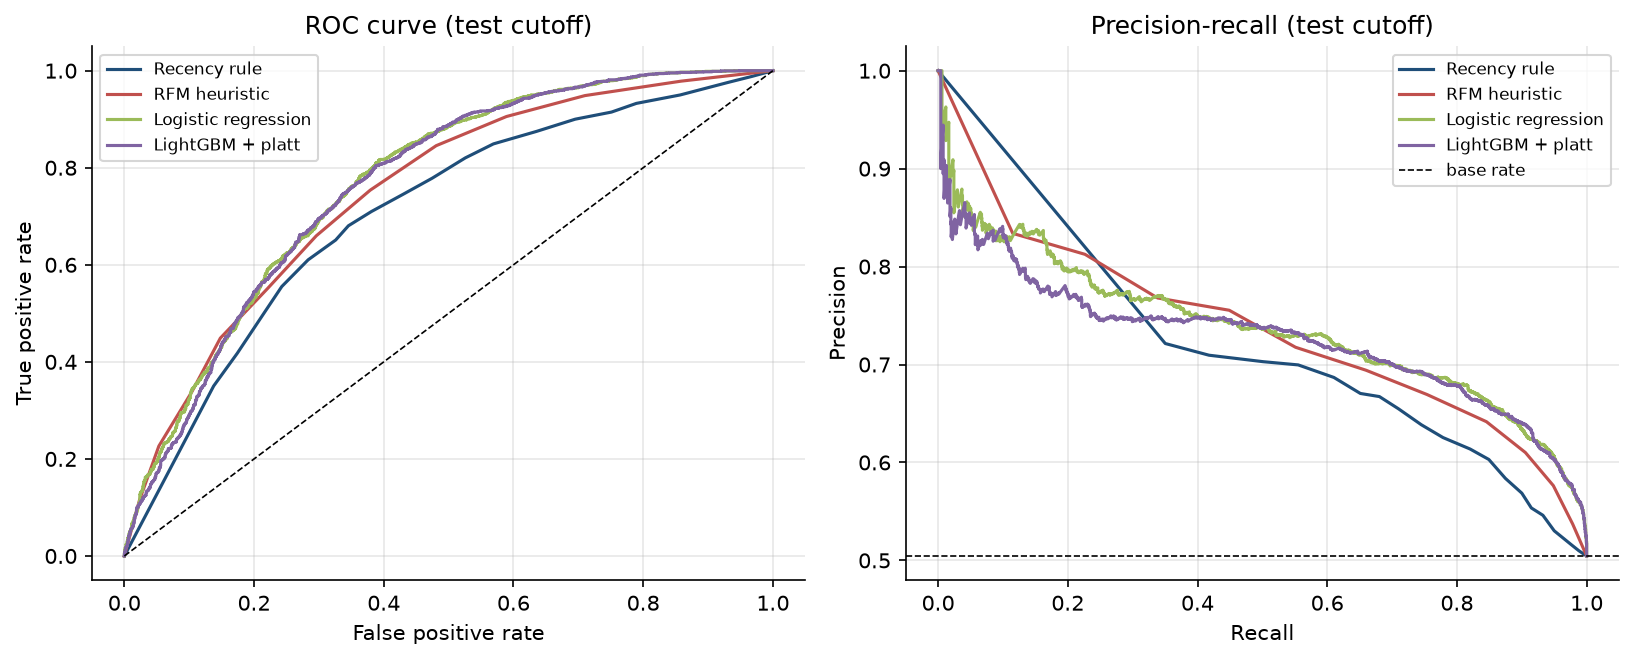

In [6]:
from IPython.display import Image; Image('docs/figures/roc_pr_test.png', width=850)

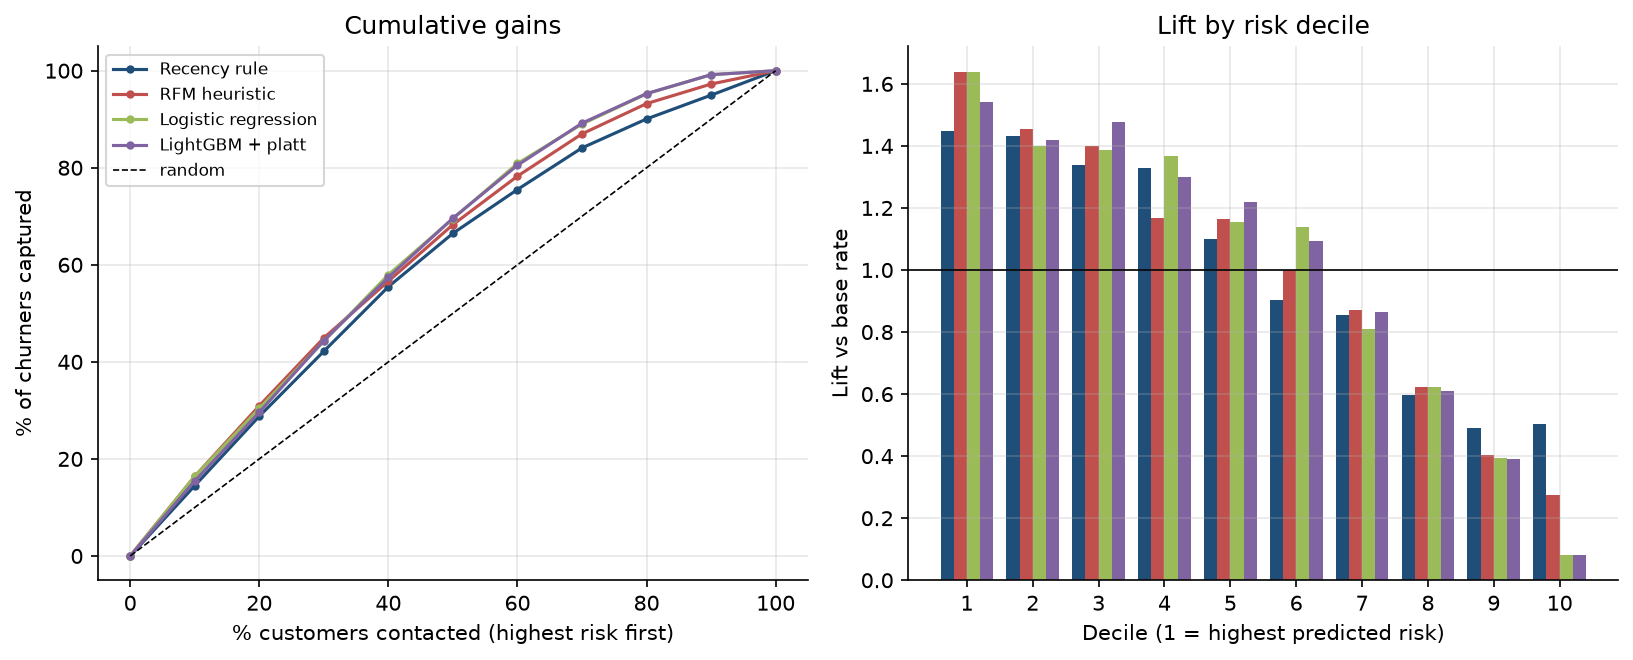

In [7]:
Image('docs/figures/gains_lift_test.png', width=850)

## Calibration

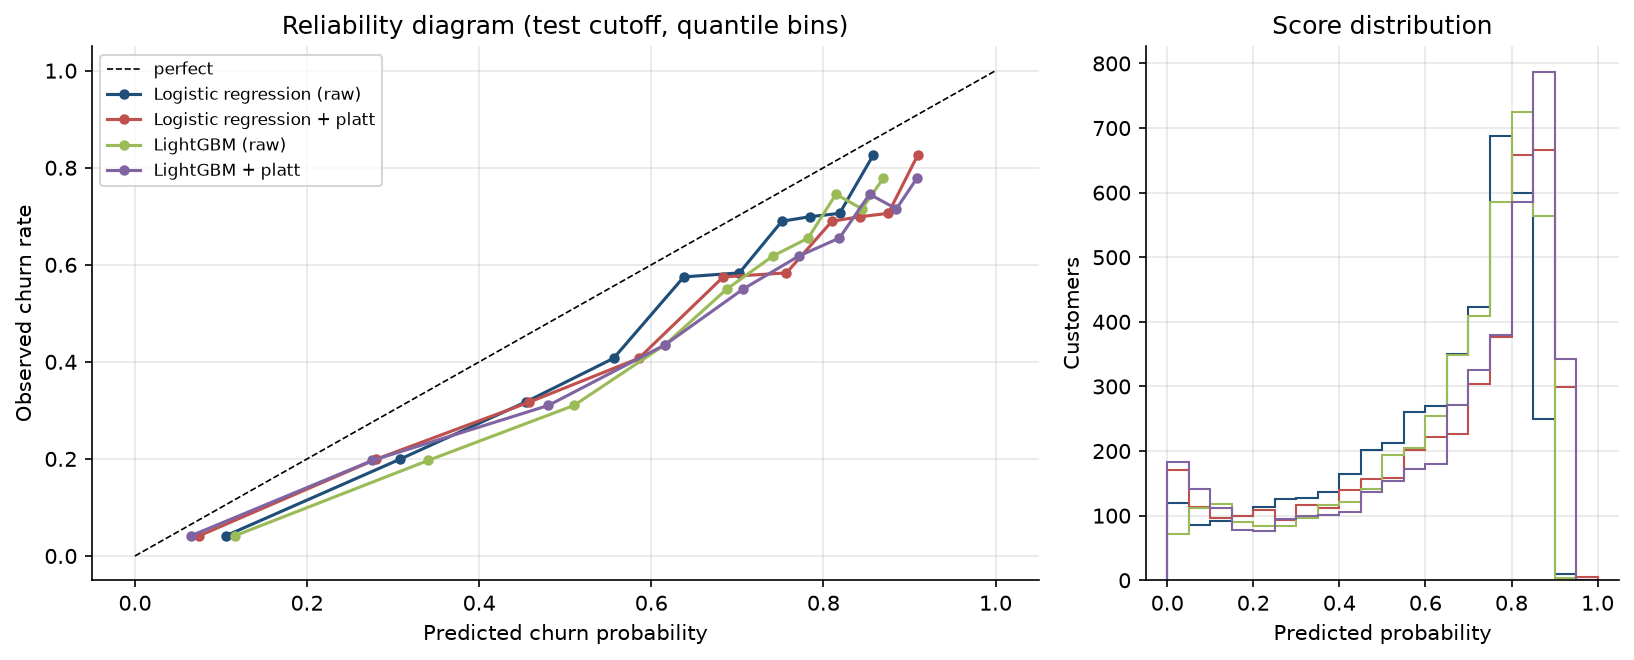

In [8]:
Image('docs/figures/reliability_test.png', width=850)

In [9]:
json.load(open(art + 'train_summary.json'))['calibration_in_the_large_test']

{'Recency rule': {'mean_pred': 0.6393971471259587,
  'observed': 0.5045107564191533},
 'RFM heuristic': {'mean_pred': 0.5475211915672926,
  'observed': 0.5045107564191533},
 'Logistic regression': {'mean_pred': 0.5975689274631882,
  'observed': 0.5045107564191533},
 'Logistic regression + platt': {'mean_pred': 0.6275904731022156,
  'observed': 0.5045107564191533},
 'LightGBM': {'mean_pred': 0.6321844988766055, 'observed': 0.5045107564191533},
 'LightGBM + platt': {'mean_pred': 0.6379936182220727,
  'observed': 0.5045107564191533}}

All models over-predict churn at the Sep-2011 cutoff: the Sep-Nov label window is peak season. Rankings remain useful; absolute probabilities need seasonal re-calibration.

## Rolling-origin backtest

In [10]:
pd.read_csv(art + 'backtest_metrics.csv')[['eval_cutoff','model','roc_auc','pr_auc','brier','base_rate']].round(3)

,eval_cutoff,model,roc_auc,pr_auc,brier,base_rate
0,2010-12-01,Recency rule,0.701,0.807,0.250,0.668
1,2010-12-01,RFM heuristic,0.774,0.845,0.239,0.668
2,2010-12-01,Logistic regression,0.789,0.857,0.238,0.668
3,2010-12-01,LightGBM,0.784,0.852,0.245,0.668
4,2011-03-01,Recency rule,0.712,0.776,0.205,0.631
5,2011-03-01,RFM heuristic,0.771,0.812,0.188,0.631
6,2011-03-01,Logistic regression,0.776,0.819,0.184,0.631
7,2011-03-01,LightGBM,0.762,0.808,0.183,0.631
8,2011-06-01,Recency rule,0.743,0.806,0.194,0.634
9,2011-06-01,RFM heuristic,0.785,0.837,0.181,0.634


## SHAP explanations

In [11]:
pd.read_csv(art + 'shap_importance.csv').head(10)

,feature,mean_abs_shap
0,active_months_12m,0.309851
1,invoices_180d,0.189960
2,revenue_180d,0.185004
3,mean_interpurchase_days,0.163219
4,tenure_days,0.144952
5,recency_to_gap_ratio,0.090731
6,revenue_90d,0.089651
7,invoices_90d,0.079227
8,std_interpurchase_days,0.071368
9,n_returns_365d,0.039028


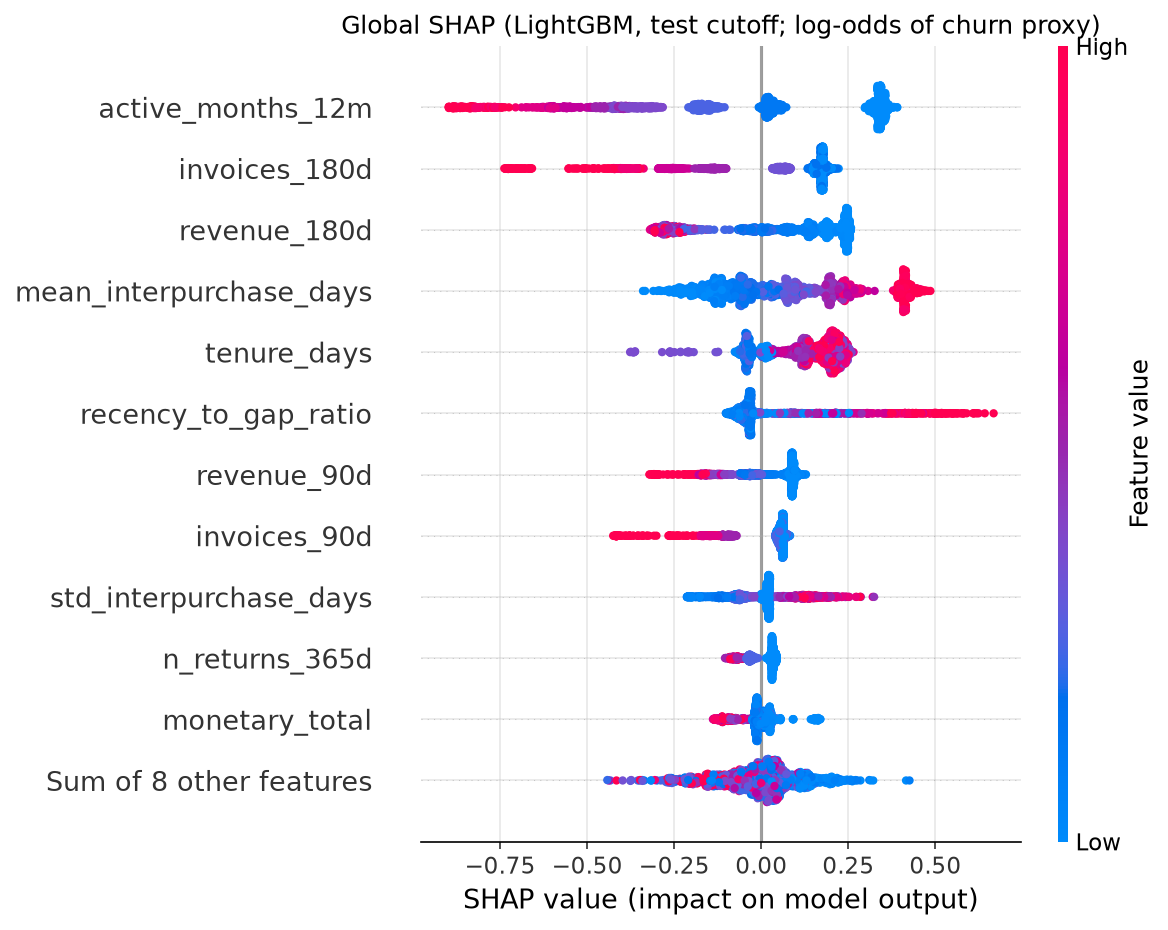

In [12]:
Image('docs/figures/shap_beeswarm.png', width=700)

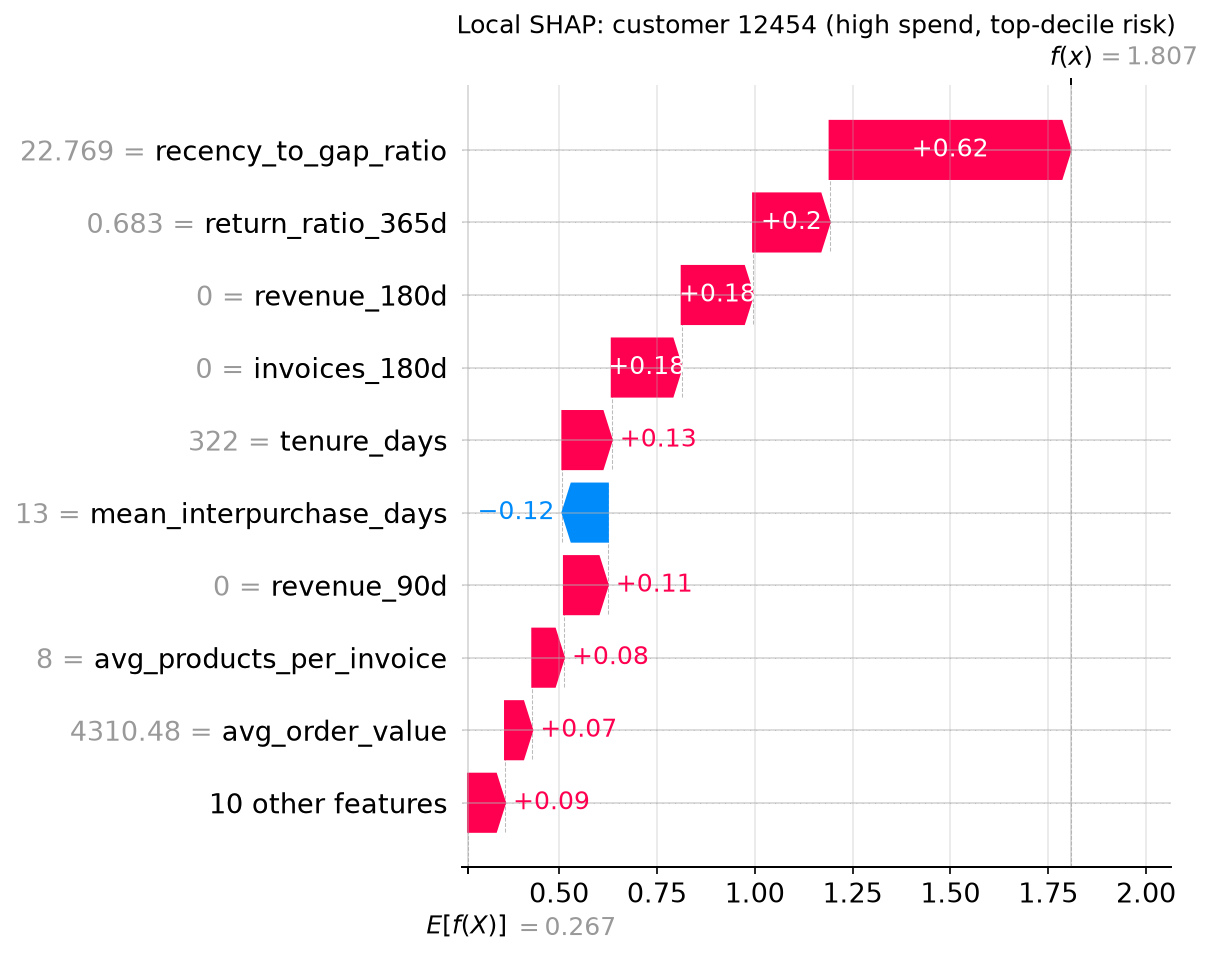

In [13]:
Image('docs/figures/shap_local_waterfall.png', width=700)

## CLV: BG/NBD + Gamma-Gamma holdout validation

In [14]:
{k: v for k, v in json.load(open(art + 'clv_summary.json')).items() if not isinstance(v, dict)}

{'holdout_days': 191.0,
 'n_customers': 4912,
 'actual_purchases_total': 8065.0,
 'pred_purchases_total': 8003.347308755081,
 'purchases_mae': 1.0840553781130673,
 'purchases_corr': 0.8495798936445211,
 'actual_spend_total': 4516804.26,
 'pred_spend_total': 3968694.029556242,
 'spend_corr': 0.9209668935629853,
 'spend_spearman': 0.5931397892233103,
 'aov_corr_repeaters': 0.8381287755485374,
 'top10_share_of_actual_spend': 0.6367195708409998,
 'scoring_as_of': '2011-09-01',
 'clv_12m_total_scored': 6784549.032220087,
 'clv_12m_median': 445.3115731013226}

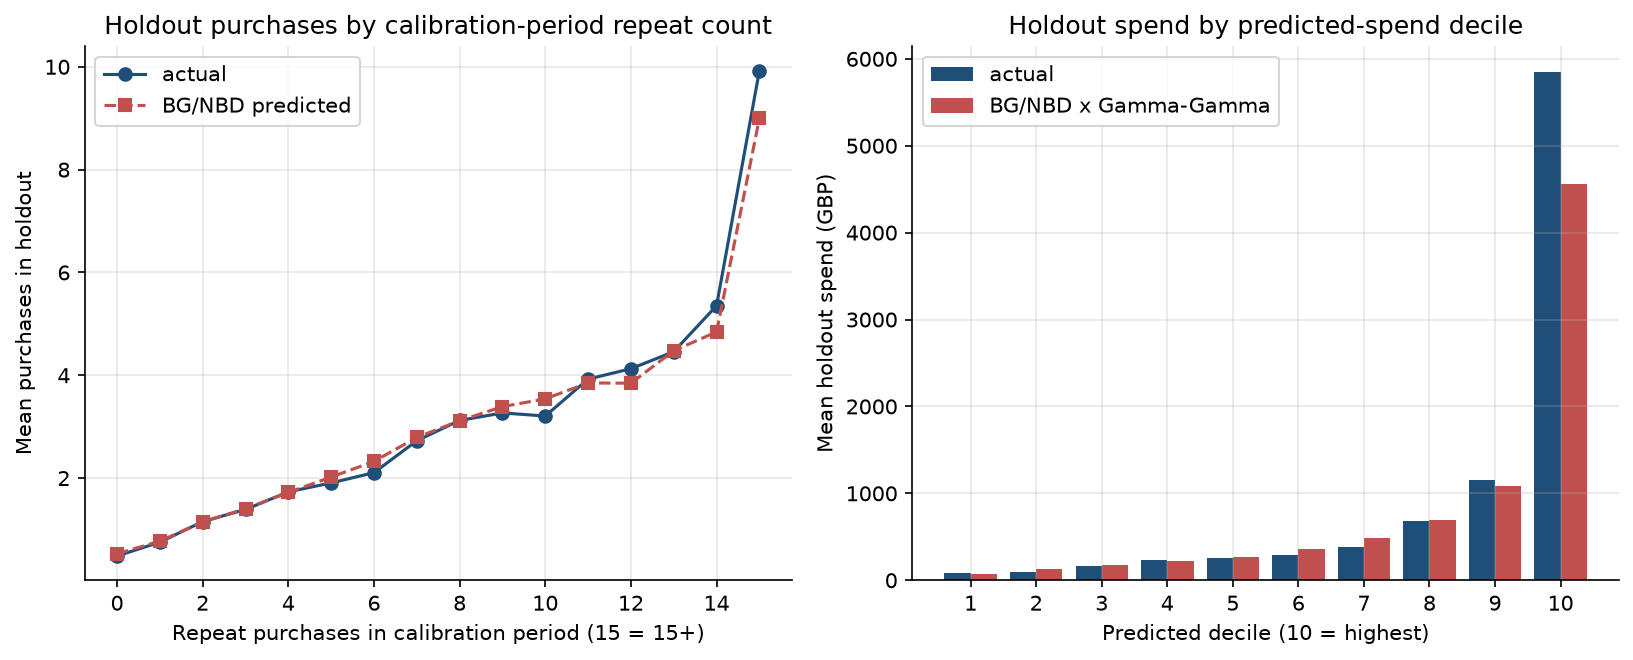

In [15]:
Image('docs/figures/clv_holdout_validation.png', width=850)

## Targeting matrix and ROI rule (ASSUMED parameters)

In [16]:
pd.read_csv(art + 'targeting_matrix.csv').round(2)

,value_segment,risk_segment,customers,mean_churn_prob,mean_clv_12m,total_clv_12m,observed_churn_rate,observed_revenue_90d
0,Low value,Low risk,100,0.48,418.88,41887.91,0.43,21380.65
1,Low value,Medium risk,744,0.73,344.77,256509.80,0.62,122084.98
2,Low value,High risk,1318,0.87,292.64,385703.59,0.75,143169.16
3,Mid value,Low risk,547,0.40,1065.32,582728.16,0.28,228220.08
4,Mid value,Medium risk,633,0.70,934.65,591635.46,0.52,233175.60
5,Mid value,High risk,116,0.85,740.00,85839.69,0.66,22579.84
6,High value,Low risk,794,0.20,5668.20,4500547.54,0.12,1811364.60
7,High value,Medium risk,64,0.66,2454.72,157102.38,0.48,64286.70
8,High value,High risk,7,0.85,2070.45,14493.16,0.43,7917.84


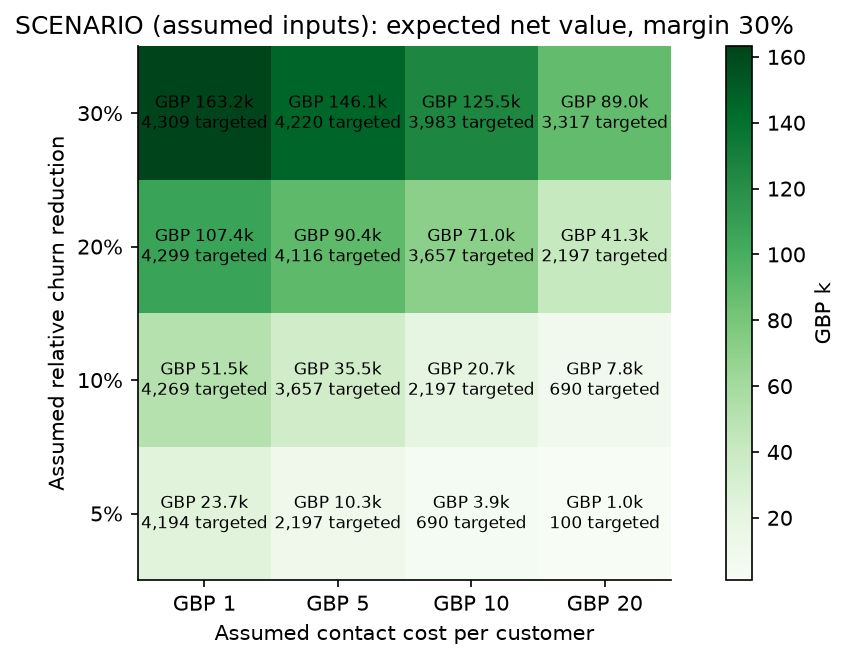

In [17]:
Image('docs/figures/targeting_sensitivity.png', width=700)